# Quick look at Sea Ice Volume

- No observations (thickness plots coming)
- Compare to OM2
- Can merged with sea ice area timeseries in the future

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/"
nbname = "SeaIce_Vol.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import os
import xarray as xr
import numpy as np
import cf_xarray
from datetime import timedelta
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client

import pandas as pd
pd.set_option('display.max_rows', 500)

In [5]:
IAF = esm_file.find('iaf') > 0
IAF

True

In [6]:
if IAF:
    om2_exp = '025deg_jra55_iaf_omip2_cycle6'
else:
    om2_exp = '025deg_jra55_ryf9091_gadi'

In [7]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37211,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40889,Total threads: 1
Dashboard: http://127.0.0.1:35891/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:40149,


### Open the intake-esm datastore

In [8]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

### Load ACCESS-OM3 sea ice data

Load grid cell area from cice variable

In [9]:
static = xr.open_dataset(datastore.search(filename="access-om3.mom6.static.nc").df.loc[0, "path"]).drop_vars("time")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1514856a1430>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151485660c80>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15148565c290>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15148565ec90>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151485659b50>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15148564b680>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15148565a240>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [10]:
tarea = static.compute().rename(areacello='tarea')

In [11]:
variables = ["hi_m", "hs_m"]
ds = datastore.search(variable=variables, frequency="1mon").to_dask(
    xarray_open_kwargs = dict(chunks={"ni": -1, "nj": -1}, # Good for spatial operations, but not temporal
                              decode_timedelta=True),
)

# give sea ice variables useful spatial coordinates
ds.coords['ni'] = static['xh'].values
ds.coords['nj'] = static['yh'].values
ds['ni'].attrs = static['xh'].attrs
ds['nj'].attrs = static['yh'].attrs
ds = ds.rename(({ 'ni': 'xh', 'nj': 'yh'}))

Integrate terms for both poles.

In [12]:
%%time
antarctic_seaice = (ds * tarea.tarea ).sel(yh=slice(None, 0)).sum(['yh','xh']).compute()
arctic_seaice = (ds * tarea.tarea ).sel(yh=slice(0, None)).sum(['yh','xh']).compute()

CPU times: user 25.5 s, sys: 12.5 s, total: 38 s
Wall time: 37.5 s


Global maximum ice and snow thickness

In [13]:
%%time
seaice_max = ds.max(['yh','xh']).compute()

CPU times: user 6.82 s, sys: 3.88 s, total: 10.7 s
Wall time: 11.1 s


### Load ACCESS-OM2

In [14]:
catalog = intake.cat.access_nri

Load grid cell area variable

In [15]:
static_om2 = xr.open_dataset(catalog[om2_exp].search(filename="ocean_grid.nc").df.loc[0, "path"]).drop_vars("time")

In [16]:
var = catalog[om2_exp].search(variable=variables,frequency="1mon")
var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
ds_om2=var.to_dask(xarray_open_kwargs=dict(chunks={"time": -1},
                                                   decode_timedelta=True,
                                                   ), 
                           xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override", data_vars="minimal", coords="minimal",),                          
)

# shift time to correct for OM2 calendar strangeness
def shift_time(ds):
    ds["time"] = ds.time.to_pandas() - timedelta(minutes=1)
    return ds

ds_om2 = shift_time(ds_om2)

# give sea ice variables useful spatial coordinates
ds_om2.coords['ni'] = static_om2['xt_ocean'].values
ds_om2.coords['nj'] = static_om2['yt_ocean'].values
ds_om2['ni'].attrs = static_om2['xt_ocean'].attrs
ds_om2['nj'].attrs = static_om2['yt_ocean'].attrs
ds_om2 = ds_om2.rename(({ 'ni': 'xt_ocean', 'nj': 'yt_ocean'}))

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='hi_m' → variable=['hi_m','hi_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='hs_m' → variable=['hs_m','hs_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)


Integrate terms for both poles.

In [17]:
%%time
antarctic_seaice_om2 = (ds_om2 * static_om2['area_t']).sel(yt_ocean=slice(None, 0)).sum(['yt_ocean','xt_ocean']).compute()
arctic_seaice_om2 = (ds_om2 * static_om2['area_t']).sel(yt_ocean=slice(0, None)).sum(['yt_ocean','xt_ocean']).compute()

CPU times: user 1min, sys: 25.7 s, total: 1min 26s
Wall time: 1min 26s


Global maximum ice and snow thickness

In [18]:
%%time
seaice_max_om2 = ds_om2.max(['yt_ocean','xt_ocean']).compute()

CPU times: user 19.8 s, sys: 8.73 s, total: 28.5 s
Wall time: 31.1 s


In [19]:
om3label = f"ACCESS-OM3: {os.path.normpath(esm_file).split(os.sep)[-2]}"
om2label = f"ACCESS-OM2: {om2_exp}"

# Sea Ice Volume timeseries

Saved /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol_01.png
Adding entry to per-notebook markdown: /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol.md


Lines appended to /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol.md successfully.


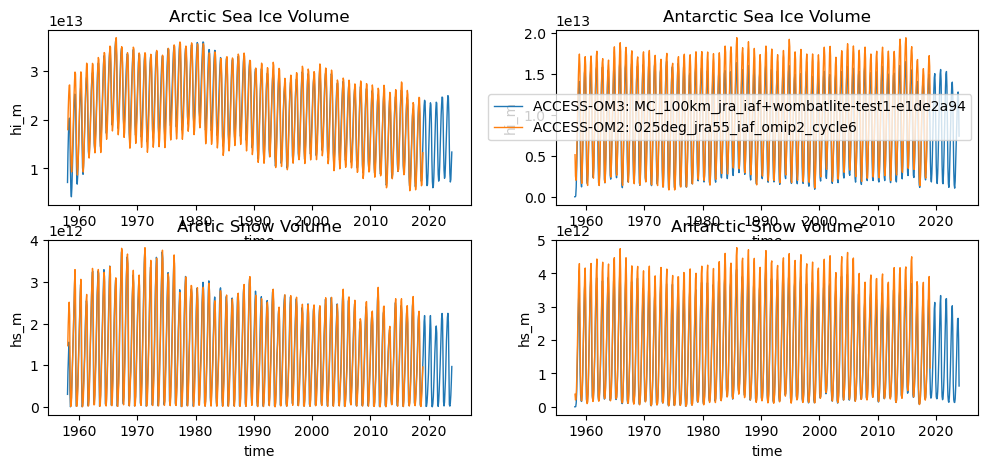

In [20]:
plt.figure(figsize=(12,5))

plt.subplot(2,2,1)
arctic_seaice.hi_m.plot(linewidth=1)
arctic_seaice_om2.hi_m.plot(linewidth=1)
plt.title('Arctic Sea Ice Volume')

plt.subplot(2,2,2)
antarctic_seaice.hi_m.plot(linewidth=1, label=om3label)
antarctic_seaice_om2.hi_m.plot(linewidth=1, label=om2label)
plt.legend()
plt.title('Antarctic Sea Ice Volume')

plt.subplot(2,2,3)
arctic_seaice.hs_m.plot(linewidth=1)
arctic_seaice_om2.hs_m.plot(linewidth=1)
plt.title('Arctic Snow Volume')

plt.subplot(2,2,4)
antarctic_seaice.hs_m.plot(linewidth=1)
antarctic_seaice_om2.hs_m.plot(linewidth=1)
plt.title('Antarctic Snow Volume')

mkmd.savefig(plt.gcf(),"Sea Ice and snow volume timeseries", "Sea Ice Volume timeseries. [GitHub issue: Sea ice volume time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/20)", dpi=150)

# Sea ice maximum thickness timeseries

Saved /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol_02.png
Adding entry to per-notebook markdown: /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol.md
Lines appended to /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SeaIce_Vol.md successfully.


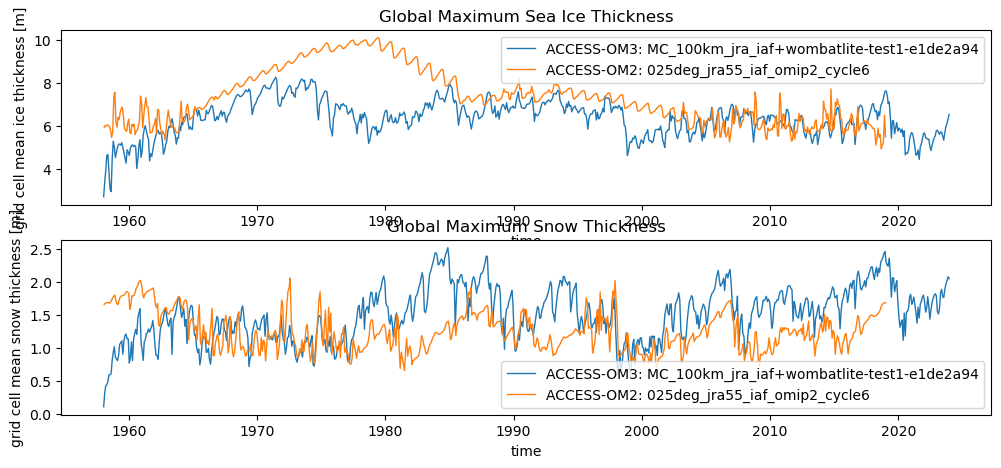

In [21]:
plt.figure(figsize=(12,5))

plt.subplot(2,1,1)
seaice_max.hi_m.plot(linewidth=1, label=om3label)
seaice_max_om2.hi_m.plot(linewidth=1, label=om2label)
plt.title('Global Maximum Sea Ice Thickness')
plt.ylabel(f"{ds.hi_m.attrs['long_name']} [{ds.hi_m.attrs['units']}]")
plt.legend()

plt.subplot(2,1,2)
seaice_max.hs_m.plot(linewidth=1, label=om3label)
seaice_max_om2.hs_m.plot(linewidth=1, label=om2label)
plt.title('Global Maximum Snow Thickness')
plt.ylabel(f"{ds.hs_m.attrs['long_name']} [{ds.hs_m.attrs['units']}]")
plt.legend()
mkmd.savefig(plt.gcf(),"Sea Ice Volume: Maximum Thickness Timeseries", "Sea Ice maximum timeseries. [GitHub issue: Sea ice thickness/concentration](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/22)", dpi=150)